In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [6]:
arquivo = files.upload()

Saving alyx_head1b.jpg to alyx_head1b.jpg


array([[209, 209, 209, ..., 209, 209, 209],
       [209, 209, 209, ..., 209, 209, 209],
       [209, 209, 209, ..., 209, 209, 209],
       ...,
       [ 13,   8,  12, ...,  48,  48,  50],
       [ 15,  12,  15, ...,  54,  51,  49],
       [ 14,  12,  14, ...,  54,  50,  52]], dtype=uint8)
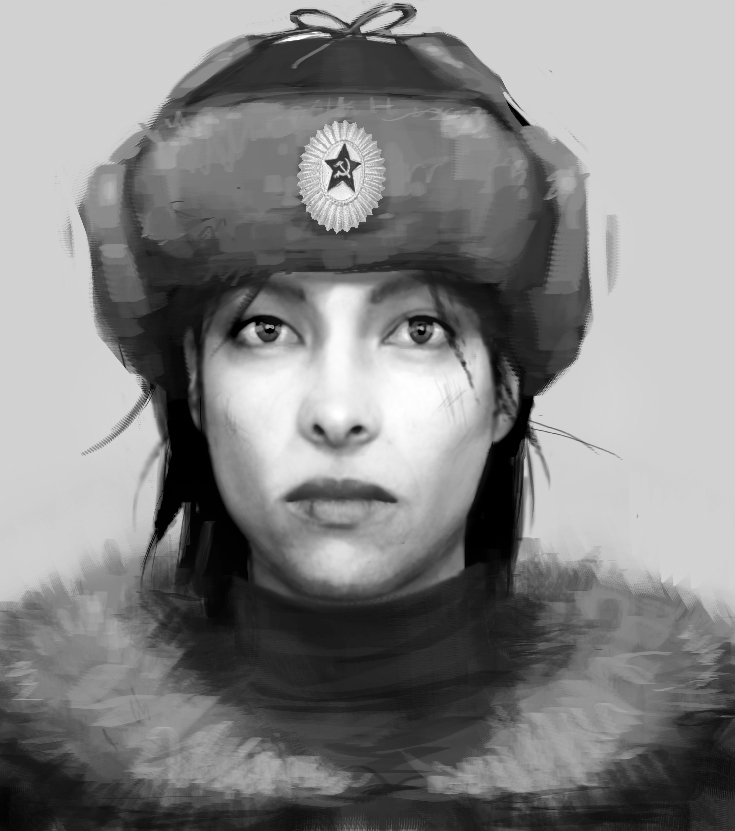

In [7]:
arquivo_imagem = next(iter(arquivo))
img_bgr = cv2.imread(arquivo_imagem)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_gray

In [10]:
def quantizacao_imagem(imagem, bits):
    levels = 2 ** bits
    steps = 256 / levels

    index = np.floor(imagem / steps)

    imagem_quantizada = index * (255 / (levels - 1))

    return np.clip(imagem_quantizada, 0, 255).astype(np.uint8)


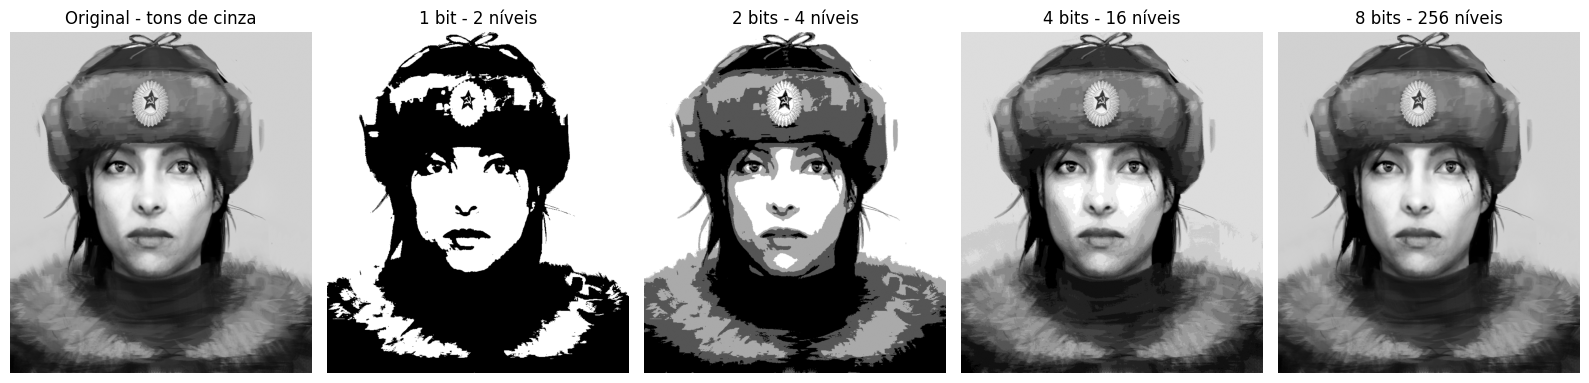

In [11]:
img_1bit = quantizacao_imagem(img_gray, 1)
img_2bit = quantizacao_imagem(img_gray, 2)
img_4bit = quantizacao_imagem(img_gray, 4)
img_8bit = quantizacao_imagem(img_gray, 8)

fig, ax = plt.subplots(1, 5, figsize=(16, 4))

ax[0].imshow(img_gray, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Original - tons de cinza")
ax[0].axis("off")

ax[1].imshow(img_1bit, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("1 bit - 2 níveis")
ax[1].axis("off")

ax[2].imshow(img_2bit, cmap="gray", vmin=0, vmax=255)
ax[2].set_title("2 bits - 4 níveis")
ax[2].axis("off")

ax[3].imshow(img_4bit, cmap="gray", vmin=0, vmax=255)
ax[3].set_title("4 bits - 16 níveis")
ax[3].axis("off")

ax[4].imshow(img_8bit, cmap="gray", vmin=0, vmax=255)
ax[4].set_title("8 bits - 256 níveis")
ax[4].axis("off")

plt.tight_layout()
plt.savefig("quantizacao.png", dpi=300, bbox_inches="tight")
plt.show()

## Resposta:
Quando número de bits da imagem é reduzido, ela vai perdendo qualidade de forma progressiva. Em 1 bit, a imagem fica apenas na coloração preta e branca, ao aumentar a quantidade de bits em duas vezes, os níveis de qualidade vão se recuperando e os detalhes melhores, com 8 bits toda a qualidade da imagem é preservada.